
# W03 — Lineerlik, TI ve Basit Sistem Bileşimleri

Bu derste; **kutular ve oklar** ile sistem fikrini pekiştirecek, **lineerlik** (homojenlik + superposition),
**TI (Time-Invariance)** testini uygulayacak ve **seri/paralel** bileşimleri **blok şema** ve grafiklerle tanıyacaksın.

## Öğrenme Hedefleri
- Basit blok şemalarıyla sistemlerin giriş–çıkış ilişkisini açıklamak
- Lineerliğin **homojenlik** ve **superposition** bileşenlerini örneklerle göstermek
- **TI** testini grafiklerle uygulamak
- **Seri** ve **paralel** bileşimlerde eşdeğer düzenek fikrini kavramak
- **LTI** ifadesini doğru yerde kullanmak


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyArrow, FancyArrowPatch
from matplotlib.lines import Line2D

np.random.seed(42)

# ---------- Blok çizim yardımcıları ----------
def draw_system_box(ax, x0=0.3, y0=0.3, w=0.4, h=0.4, label='Sistem'):
    rect = Rectangle((x0, y0), w, h, fill=False, linewidth=2)
    ax.add_patch(rect)
    ax.text(x0 + w/2, y0 + h/2, label, ha='center', va='center', fontsize=12)
    ax.add_patch(FancyArrow(x0-0.2, y0+h/2, 0.18, 0, width=0.003, length_includes_head=True))
    ax.text(x0-0.23, y0+h/2, 'x[n]', ha='right', va='center')
    ax.add_patch(FancyArrow(x0+w, y0+h/2, 0.2, 0, width=0.003, length_includes_head=True))
    ax.text(x0+w+0.22, y0+h/2, 'y[n]', ha='left', va='center')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

def draw_gain(ax, x=0.1, y=0.5, w=0.25, h=0.2, a=2.0):
    rect = Rectangle((x, y-h/2), w, h, fill=False, linewidth=2)
    ax.add_patch(rect)
    ax.text(x+w/2, y, f'×{a}', ha='center', va='center', fontsize=12)
    ax.add_patch(FancyArrow(x-0.08, y, 0.07, 0, width=0.003, length_includes_head=True))
    ax.add_patch(FancyArrow(x+w, y, 0.08, 0, width=0.003, length_includes_head=True))
    ax.text(x-0.1, y, 'giriş', ha='right', va='center', fontsize=9)
    ax.text(x+w+0.1, y, 'çıkış', ha='left', va='center', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

def draw_delay(ax, x=0.1, y=0.5, w=0.25, h=0.2):
    rect = Rectangle((x, y-h/2), w, h, fill=False, linewidth=2)
    ax.add_patch(rect)
    ax.text(x+w/2, y, 'z$^{-1}$', ha='center', va='center', fontsize=12)
    ax.add_patch(FancyArrow(x-0.08, y, 0.07, 0, width=0.003, length_includes_head=True))
    ax.add_patch(FancyArrow(x+w, y, 0.08, 0, width=0.003, length_includes_head=True))
    ax.text(x-0.1, y, 'giriş', ha='right', va='center', fontsize=9)
    ax.text(x+w+0.1, y, 'çıkış', ha='left', va='center', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

def draw_adder(ax, x=0.5, y=0.5, r=0.06):
    c = Circle((x, y), r, fill=False, linewidth=2)
    ax.add_patch(c)
    ax.text(x, y, '+', ha='center', va='center', fontsize=12)
    ax.add_patch(FancyArrow(x-0.15, y, 0.12, 0, width=0.003, length_includes_head=True))
    ax.add_patch(FancyArrow(x, y-0.15, 0, 0.12, width=0.003, length_includes_head=True))
    ax.add_patch(FancyArrow(x+r, y, 0.2, 0, width=0.003, length_includes_head=True))
    ax.text(x-0.17, y, 'giriş 1', ha='right', va='center', fontsize=9)
    ax.text(x, y-0.17, 'giriş 2', ha='center', va='top', fontsize=9)
    ax.text(x+0.22, y, 'çıkış', ha='left', va='center', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

def draw_series_diagram(ax, a=1.2, k=2, b=0.7):
    # giriş oku
    ax.add_patch(FancyArrow(0.05, 0.5, 0.1, 0, width=0.003, length_includes_head=True))
    # kazanç a
    rect1 = Rectangle((0.16, 0.4), 0.16, 0.2, fill=False, linewidth=2); ax.add_patch(rect1)
    ax.text(0.24, 0.5, f'×{a}', ha='center', va='center')
    ax.add_patch(FancyArrow(0.32, 0.5, 0.05, 0, width=0.003, length_includes_head=True))
    # gecikme z^-1
    rect2 = Rectangle((0.37, 0.4), 0.16, 0.2, fill=False, linewidth=2); ax.add_patch(rect2)
    ax.text(0.45, 0.5, 'z$^{-1}$', ha='center', va='center')
    ax.add_patch(FancyArrow(0.53, 0.5, 0.05, 0, width=0.003, length_includes_head=True))
    # kazanç b
    rect3 = Rectangle((0.58, 0.4), 0.16, 0.2, fill=False, linewidth=2); ax.add_patch(rect3)
    ax.text(0.66, 0.5, f'×{b}', ha='center', va='center')
    # çıkış oku
    ax.add_patch(FancyArrow(0.74, 0.5, 0.2, 0, width=0.003, length_includes_head=True))
    ax.text(0.03, 0.5, 'x[n]', ha='right', va='center'); ax.text(0.96, 0.5, 'y[n]', ha='left', va='center')
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')

def draw_parallel_diagram(ax, a=1.5, k=3, b=0.5):
    # giriş oku
    ax.add_patch(FancyArrow(0.05, 0.5, 0.1, 0, width=0.003, length_includes_head=True))
    ax.text(0.03, 0.5, 'x[n]', ha='right', va='center')
    # üst kol: kazanç a
    rectU = Rectangle((0.2, 0.65), 0.16, 0.2, fill=False, linewidth=2); ax.add_patch(rectU)
    ax.text(0.28, 0.75, f'×{a}', ha='center', va='center')
    # alt kol: gecikme ve kazanç b
    rectD1 = Rectangle((0.2, 0.15), 0.16, 0.2, fill=False, linewidth=2); ax.add_patch(rectD1)
    ax.text(0.28, 0.25, 'z$^{-1}$', ha='center', va='center')
    rectD2 = Rectangle((0.42, 0.15), 0.16, 0.2, fill=False, linewidth=2); ax.add_patch(rectD2)
    ax.text(0.50, 0.25, f'×{b}', ha='center', va='center')
    # bağlantılar
    ax.add_line(Line2D([0.15,0.2],[0.5,0.75],linewidth=2))
    ax.add_line(Line2D([0.15,0.2],[0.5,0.25],linewidth=2))
    ax.add_patch(FancyArrow(0.36,0.75,0.06,0,width=0.003,length_includes_head=True))
    ax.add_patch(FancyArrow(0.36,0.25,0.06,0,width=0.003,length_includes_head=True))
    ax.add_patch(FancyArrow(0.58,0.25,0.10,0,width=0.003,length_includes_head=True))
    # toplayıcı
    circ = Circle((0.72, 0.5), 0.05, fill=False, linewidth=2); ax.add_patch(circ)
    ax.text(0.72, 0.5, '+', ha='center', va='center')
    ax.add_line(Line2D([0.42,0.67],[0.75,0.5],linewidth=2))
    ax.add_line(Line2D([0.68,0.68],[0.25,0.5],linewidth=2))
    # çıkış
    ax.add_patch(FancyArrow(0.77,0.5,0.18,0,width=0.003,length_includes_head=True))
    ax.text(0.96, 0.5, 'y[n]', ha='left', va='center')
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')

# ---------- Sayısal blok fonksiyonları ----------
def kazanc(x, a): return a * x

def gecikme(x, k):
    y = np.zeros_like(x)
    if k >= 0:
        y[k:] = x[:-k] if k != 0 else x
    else:
        kk = -k; y[:-kk] = x[kk:]
    return y

def toplayici(*signals): return np.sum(np.stack(signals, axis=0), axis=0)

def seri(S1, S2): return lambda x: S2(S1(x))
def paralel(S1, S2): return lambda x: toplayici(S1(x), S2(x))

# ---------- Örnek sistemler ----------
def S_lineer1_factory():
    def S(x): return toplayici(kazanc(x, 2.0), gecikme(x, 1))
    return S

def S_mutlak_factory():
    def S(x): return np.abs(x)
    return S

def S_zamanla_degisen_factory():
    def S(x):
        n = np.arange(len(x))
        a = 1.0 + 0.3*np.sin(0.1*np.pi*n)
        return a * x
    return S

# ---------- Test yardımcıları ----------
def test_superposition(S, x1, x2, a, b):
    lhs = S(a*x1 + b*x2); rhs = a*S(x1) + b*S(x2)
    return np.allclose(lhs, rhs, atol=1e-8), lhs, rhs

def test_ti(S, x, kayma):
    y = S(x); x_k = gecikme(x, kayma); y_from_xk = S(x_k); y_k = gecikme(y, kayma)
    return np.allclose(y_from_xk, y_k, atol=1e-8), y, y_from_xk, y_k

# ---------- Çizim yardımcıları: ayrı eksenler ----------
def plot_in_out(n, x, y, title_in='Giriş x[n]', title_out='Çıkış y[n]'):
    fig, axs = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
    axs[0].plot(n, x); axs[0].set_title(title_in); axs[0].set_ylabel('genlik'); axs[0].grid(True)
    axs[1].plot(n, y); axs[1].set_title(title_out); axs[1].set_xlabel('n'); axs[1].set_ylabel('genlik'); axs[1].grid(True)
    plt.tight_layout(); plt.show()

def plot_pair(n, a_series, b_series, a_label, b_label, title=None):
    fig, axs = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
    axs[0].plot(n, a_series); axs[0].set_title(a_label); axs[0].set_ylabel('genlik'); axs[0].grid(True)
    axs[1].plot(n, b_series); axs[1].set_title(b_label); axs[1].set_xlabel('n'); axs[1].set_ylabel('genlik'); axs[1].grid(True)
    if title: fig.suptitle(title); plt.tight_layout(); plt.show()



## 1) Blok Şema: Sistem, Kazanç, Gecikme, Toplayıcı

Önce temel bileşenlerin **şematik** gösterimlerini çizelim.


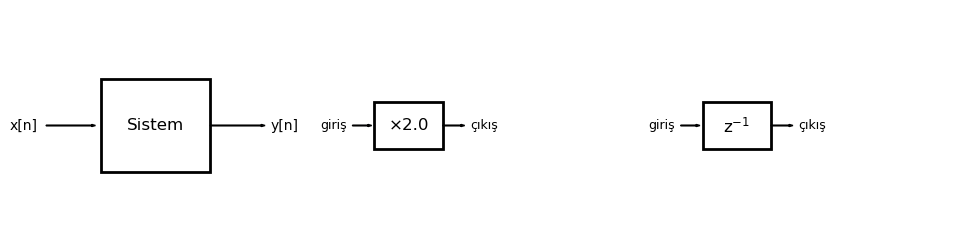

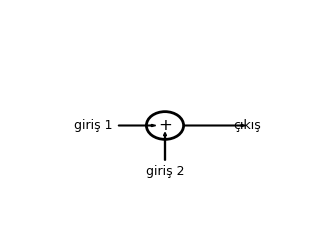

In [2]:

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
draw_system_box(axes[0], label='Sistem')
draw_gain(axes[1], a=2.0)
draw_delay(axes[2])
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(4, 3))
draw_adder(ax)
plt.show()



## 2) Giriş–Çıkış Grafikleri (Ayrı Eksenler)

Aşağıda kısa bir darbe sinyali, sırasıyla **kazanç**, **gecikme** ve **toplayıcı**dan geçirilmiştir.
Giriş ve çıkış **ayrı eksenlerde** gösterilir.


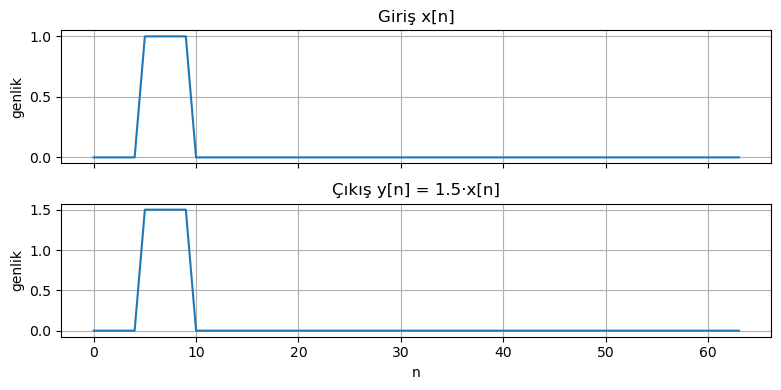

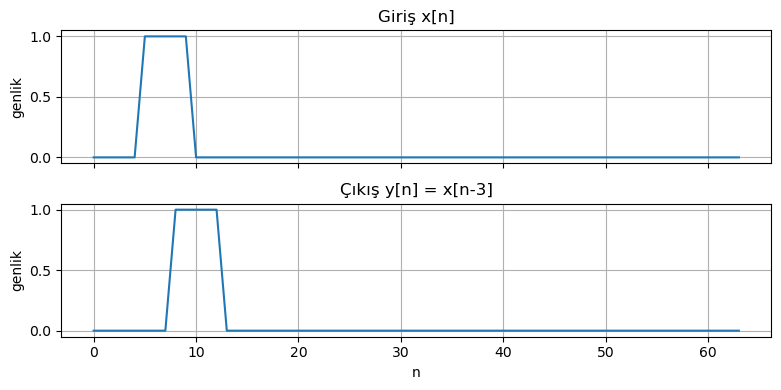

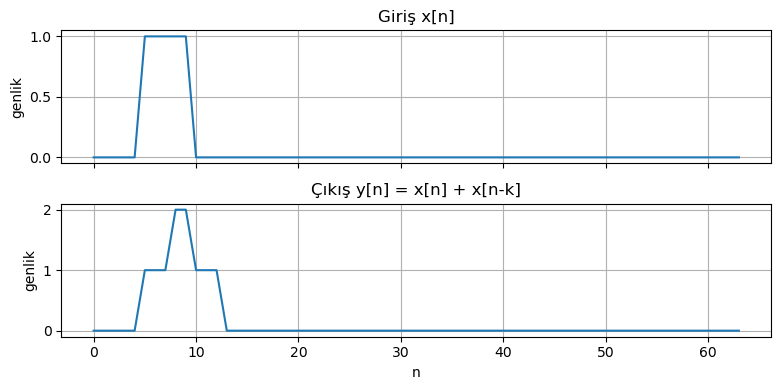

In [3]:

N = 64; n = np.arange(N)
x = np.zeros(N); x[5:10] = 1.0

# Kazanç
g = 1.5; y_gain = kazanc(x, g)
plot_in_out(n, x, y_gain, title_in='Giriş x[n]', title_out=f'Çıkış y[n] = {g}·x[n]')

# Gecikme
k = 3; y_delay = gecikme(x, k)
plot_in_out(n, x, y_delay, title_in='Giriş x[n]', title_out=f'Çıkış y[n] = x[n-{k}]')

# Toplayıcı
y_sum = toplayici(x, y_delay)
plot_in_out(n, x, y_sum, title_in='Giriş x[n]', title_out='Çıkış y[n] = x[n] + x[n-k]')



## 3) Lineerlik — Homojenlik ve **Superposition**

İki sistem üzerinde **birden fazla (a,b)** çiftiyle superposition testini yapalım:
- **S₁ (lineer):** `y[n] = 2x[n] + x[n-1]`
- **S₂ (lineer değil):** `y[n] = |x[n]|`

Aşağıda, her (a,b) çifti için **ayrı eksenlerde** sol tarafta `S(a·x₁+b·x₂)`, sağ tarafta `a·S(x₁)+b·S(x₂)` gösterilir.


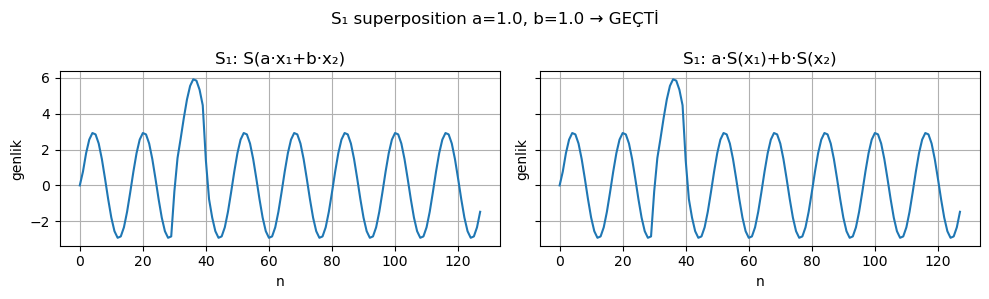

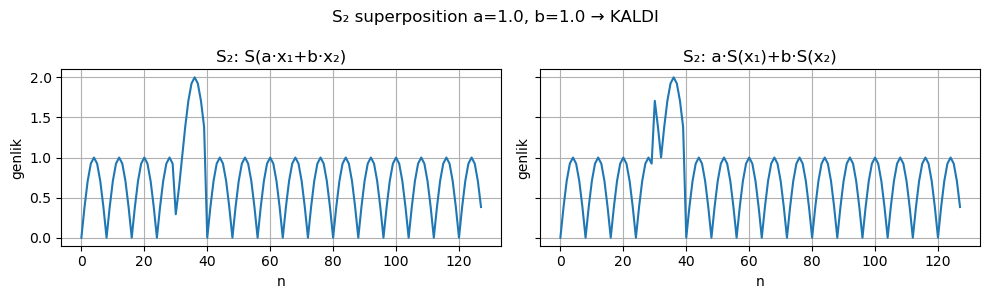

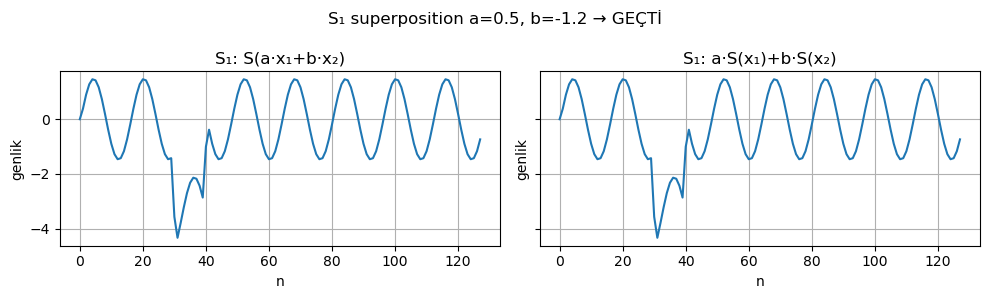

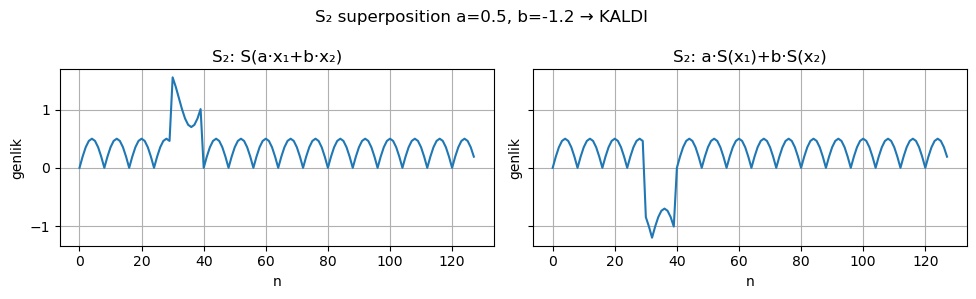

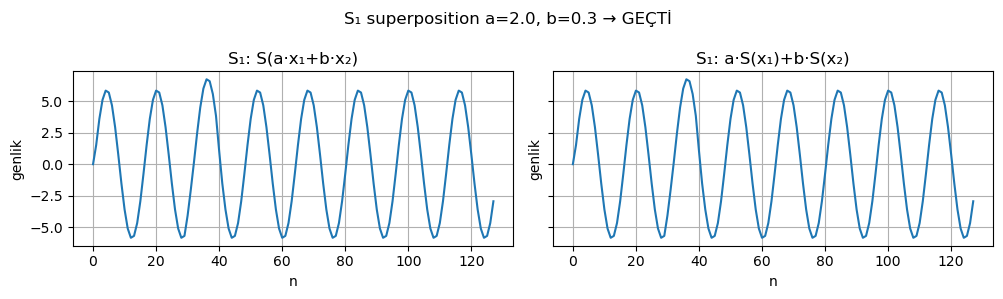

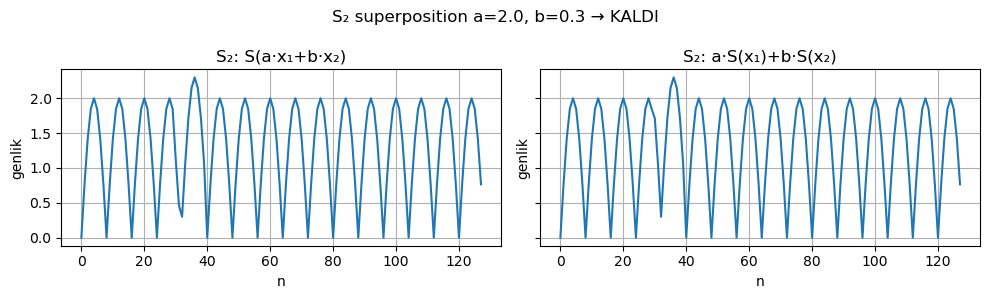

In [4]:

N = 128; n = np.arange(N)
x1 = np.sin(2*np.pi*(n/16.0))
x2 = np.zeros(N); x2[30:40] = 1.0

S1 = S_lineer1_factory()
S2 = S_mutlak_factory()

ab_list = [(1.0, 1.0), (0.5, -1.2), (2.0, 0.3)]
for (a, b) in ab_list:
    ok1, lhs1, rhs1 = test_superposition(S1, x1, x2, a, b)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
    axs[0].plot(n, lhs1); axs[0].set_title(f"S₁: S(a·x₁+b·x₂)")
    axs[1].plot(n, rhs1); axs[1].set_title(f"S₁: a·S(x₁)+b·S(x₂)")
    for ax in axs:
        ax.set_xlabel('n'); ax.set_ylabel('genlik'); ax.grid(True)
    fig.suptitle(f"S₁ superposition a={a}, b={b} → {'GEÇTİ' if ok1 else 'KALDI'}")
    plt.tight_layout(); plt.show()

    ok2, lhs2, rhs2 = test_superposition(S2, x1, x2, a, b)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
    axs[0].plot(n, lhs2); axs[0].set_title(f"S₂: S(a·x₁+b·x₂)")
    axs[1].plot(n, rhs2); axs[1].set_title(f"S₂: a·S(x₁)+b·S(x₂)")
    for ax in axs:
        ax.set_xlabel('n'); ax.set_ylabel('genlik'); ax.grid(True)
    fig.suptitle(f"S₂ superposition a={a}, b={b} → {'GEÇTİ' if ok2 else 'KALDI'}")
    plt.tight_layout(); plt.show()



## 4) **TI (Time-Invariance)** Testi

Girişi `n₀` kadar kaydırdığımızda, çıktı da **aynı** miktarda kaymalı mıdır?
Her kayma için solda `x[n-n₀]`'den elde edilen `y`, sağda ise `x[n]`'den elde edilen `y`’nin kaydırılmış hali gösterilir.


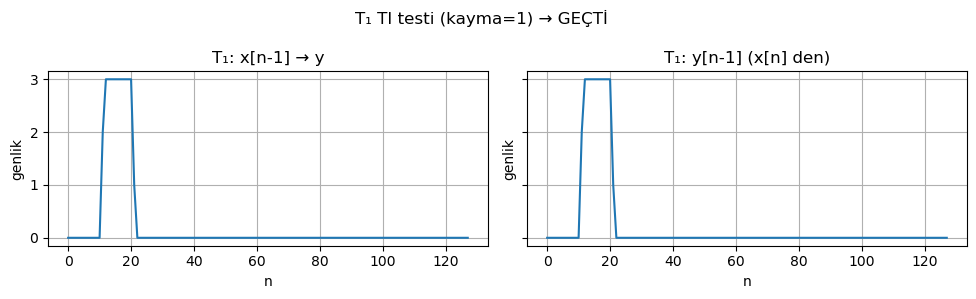

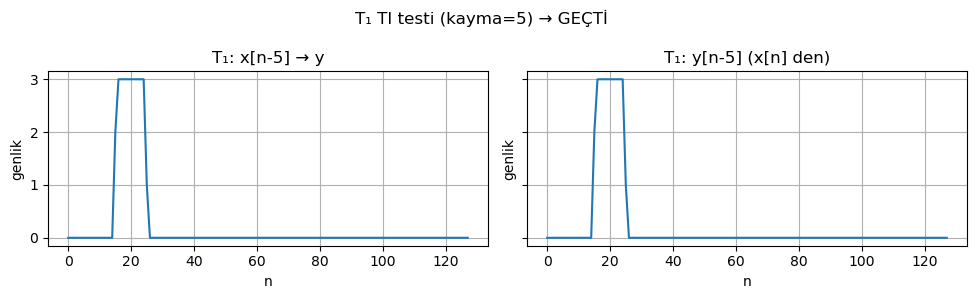

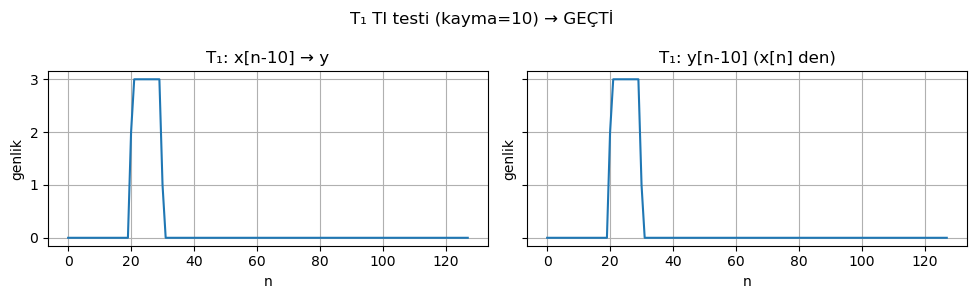

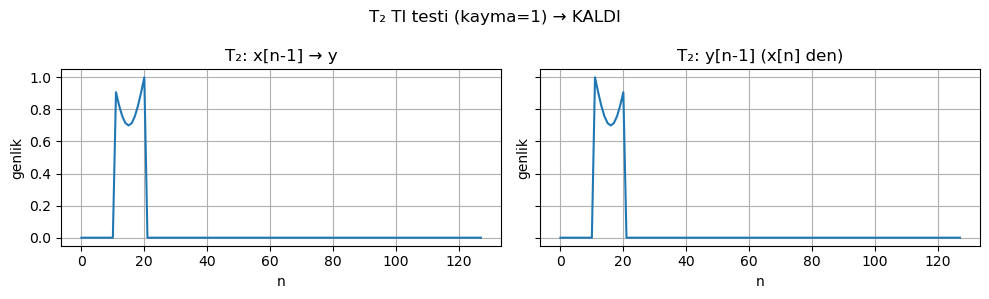

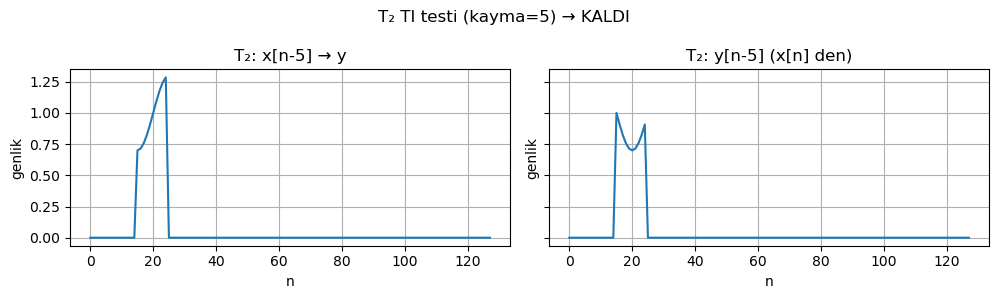

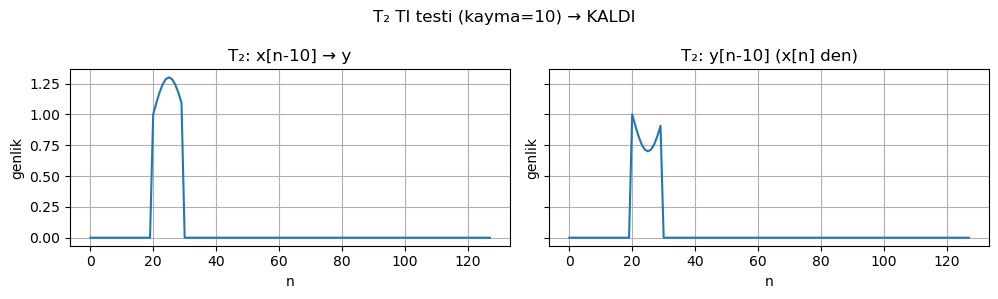

In [5]:

N = 128; n = np.arange(N)
x = np.zeros(N); x[10:20] = 1.0
kaymalar = [1, 5, 10]

T1 = S_lineer1_factory()
T2 = S_zamanla_degisen_factory()

for k in kaymalar:
    ok1, y, y_from_xk, y_k = test_ti(T1, x, k)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
    axs[0].plot(n, y_from_xk); axs[0].set_title(f"T₁: x[n-{k}] → y")
    axs[1].plot(n, y_k);       axs[1].set_title(f"T₁: y[n-{k}] (x[n] den)")
    for ax in axs:
        ax.set_xlabel('n'); ax.set_ylabel('genlik'); ax.grid(True)
    fig.suptitle(f"T₁ TI testi (kayma={k}) → {'GEÇTİ' if ok1 else 'KALDI'}")
    plt.tight_layout(); plt.show()

for k in kaymalar:
    ok2, y, y_from_xk, y_k = test_ti(T2, x, k)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
    axs[0].plot(n, y_from_xk); axs[0].set_title(f"T₂: x[n-{k}] → y")
    axs[1].plot(n, y_k);       axs[1].set_title(f"T₂: y[n-{k}] (x[n] den)")
    for ax in axs:
        ax.set_xlabel('n'); ax.set_ylabel('genlik'); ax.grid(True)
    fig.suptitle(f"T₂ TI testi (kayma={k}) → {'GEÇTİ' if ok2 else 'KALDI'}")
    plt.tight_layout(); plt.show()



## 5) Seri ve Paralel Bileşimler — Blok Şema + Ayrı Eksenlerde Giriş/Çıkış

Aşağıda önce **blok şema** çiziliyor, ardından aynı düzenek için **giriş–çıkış** grafikleri **ayrı eksenlerde** veriliyor.


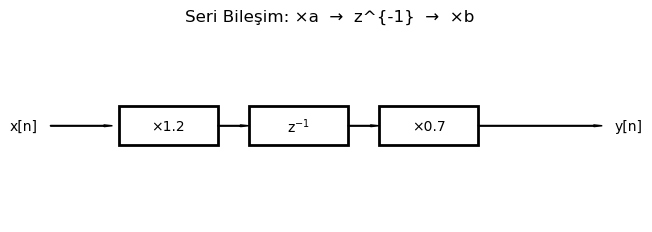

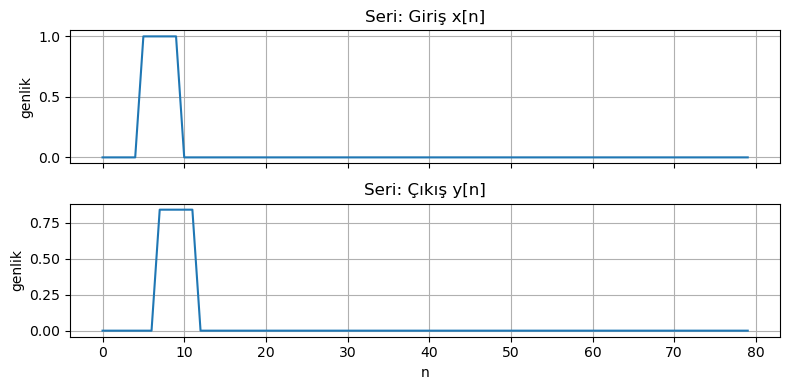

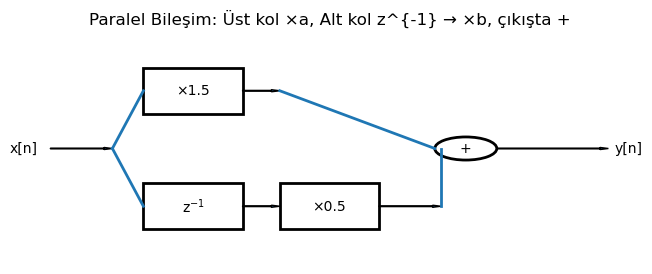

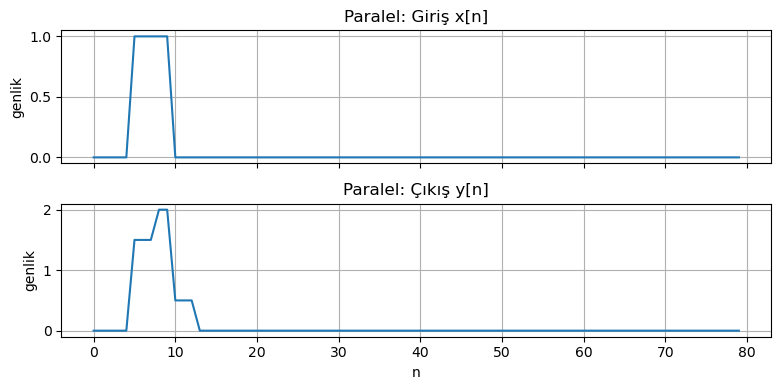

In [6]:

# --- SERİ ---
fig, ax = plt.subplots(1,1, figsize=(8,2.5))
draw_series_diagram(ax, a=1.2, k=2, b=0.7)
plt.title('Seri Bileşim: ×a  →  z^{-1}  →  ×b')
plt.show()

def seri_ornek_factory(a=1.2, k=2, b=0.7):
    S = seri(lambda x: kazanc(x, a), lambda x: gecikme(x, k))
    S = seri(S, lambda x: kazanc(x, b))
    return S, a*b, k

N = 80; n = np.arange(N)
x = np.zeros(N); x[5:10] = 1.0
S, es_kazanc, es_gecikme = seri_ornek_factory()
y_seri = S(x)
# ayrı eksenlerde göster
plot_in_out(n, x, y_seri, title_in='Seri: Giriş x[n]', title_out='Seri: Çıkış y[n]')

# --- PARALEL ---
fig, ax = plt.subplots(1,1, figsize=(8,3))
draw_parallel_diagram(ax, a=1.5, k=3, b=0.5)
plt.title('Paralel Bileşim: Üst kol ×a, Alt kol z^{-1} → ×b, çıkışta +')
plt.show()

def paralel_ornek_factory(a=1.5, k=3, b=0.5):
    K1 = lambda x: kazanc(x, a)
    K2 = seri(lambda x: gecikme(x, k), lambda x: kazanc(x, b))
    P = paralel(K1, K2)
    return P, a, (k, b)

P, a, (k, b) = paralel_ornek_factory()
y_paralel = P(x)
plot_in_out(n, x, y_paralel, title_in='Paralel: Giriş x[n]', title_out='Paralel: Çıkış y[n]')



## 6) Mini-Lab

1. **Superposition (çoklu (a,b))**  
   `S = 2x[n] + x[n-1]` ve `S = |x[n]|` için `(a,b) ∈ {(1,1),(0.5,-1.2),(2,0.3)}` setinde superposition sağlanıp sağlanmadığını test et ve kısaca yorumla.

2. **TI testi**  
   `n₀ ∈ {1,5,10}` için `y[n] = 2x[n] + x[n-1]` ve `y[n] = (1 + 0.3·sin(0.1πn)) · x[n]`.  
   Hangi sistem(ler) tüm kaymalarda TI?

3. **Seri → Eşdeğer**  
   (kazanç `a`) → (gecikme `k`) → (kazanç `b`) serisini eşdeğer tek blokla ifade et ve kısa bir sayısal örnekle doğrula.



## 7) Kapanış
- Lineerlik = **homojenlik + superposition**.  
- **TI**: girişteki kaydırma, çıktıda **aynı** kaydırmadır.  
- **Seri/Paralel**: basit bloklar düşünülerek **eşdeğer** yapılara indirgenebilir.  
- **LTI**: hem lineer hem TI olan sistemler.
